# Disruption Detection: ML Classifier Evaluation

This notebook evaluates the Component 4 disruption-detection stack: the
rule-based baseline, the ML-only classifiers, and the hybrid rules + ML fusion.
It reads the JSON artefacts produced by the training and evaluation scripts:

- `results_rules_only.json`, `results_ml_only.json`, `results_hybrid.json`
- `results_train_disruption.json`, `results_train_severity.json`
- `results_ablation.json`, `results_latency.json`

Run the scripts first (from the backend root, inside the project virtualenv):

```
python -m app.replanning.disruption_detection.classifiers.generate_disruption_data
python -m app.replanning.disruption_detection.classifiers.train_disruption_classifier
python -m app.replanning.disruption_detection.classifiers.train_severity_classifier
python -m app.replanning.disruption_detection.classifiers.evaluate_rules_only
python -m app.replanning.disruption_detection.classifiers.evaluate_ml_only
python -m app.replanning.disruption_detection.classifiers.evaluate_hybrid
python -m app.replanning.disruption_detection.classifiers.run_ablation_study
python -m app.replanning.disruption_detection.classifiers.measure_latency
```

Figures are written to `data/disruption_detection/plots/`.

## 0. Setup and artefact loading

In [2]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110


def find_backend_root() -> Path:
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "data" / "disruption_detection").is_dir():
            return base
    return Path.cwd()


ROOT = find_backend_root()
DATA_DIR = ROOT / "data" / "disruption_detection"
PLOT_DIR = DATA_DIR / "plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)


def load_result(name):
    path = DATA_DIR / f"results_{name}.json"
    if not path.exists():
        print(f"[skip] missing {path.name}")
        return None
    with path.open(encoding="utf-8") as handle:
        return json.load(handle)


rules = load_result("rules_only")
ml = load_result("ml_only")
hybrid = load_result("hybrid")
train_presence = load_result("train_disruption")
train_severity = load_result("train_severity")
ablation = load_result("ablation")
latency = load_result("latency")

loaded = {
    "rules_only": rules,
    "ml_only": ml,
    "hybrid": hybrid,
    "train_disruption": train_presence,
    "train_severity": train_severity,
    "ablation": ablation,
    "latency": latency,
}
print("Loaded artefacts:", [name for name, value in loaded.items() if value])
print("Backend root:", ROOT)

Loaded artefacts: ['rules_only', 'ml_only', 'hybrid', 'train_disruption', 'train_severity', 'ablation', 'latency']
Backend root: D:\Research\project\J26-DS-337\wandaraya-backend


## 1. Presence metrics summary

In [3]:
rows = []
for name, result in [("rules_only", rules), ("ml_only", ml), ("hybrid", hybrid)]:
    if not result:
        continue
    presence = result["presence"]
    rows.append({
        "variant": name,
        "accuracy": presence["accuracy"],
        "precision": presence["precision"],
        "recall": presence["recall"],
        "f1": presence["f1"],
        "roc_auc": presence["roc_auc"],
    })

summary = pd.DataFrame(rows).set_index("variant")
summary

,accuracy,precision,recall,f1,roc_auc
variant,,,,,
rules_only,0.8133,0.9167,0.7500,0.8250,0.6979
ml_only,0.8067,0.8933,0.7614,0.8221,0.8920
hybrid,0.9067,0.9302,0.9091,0.9195,0.8920


## 2. ROC curve (disruption presence)

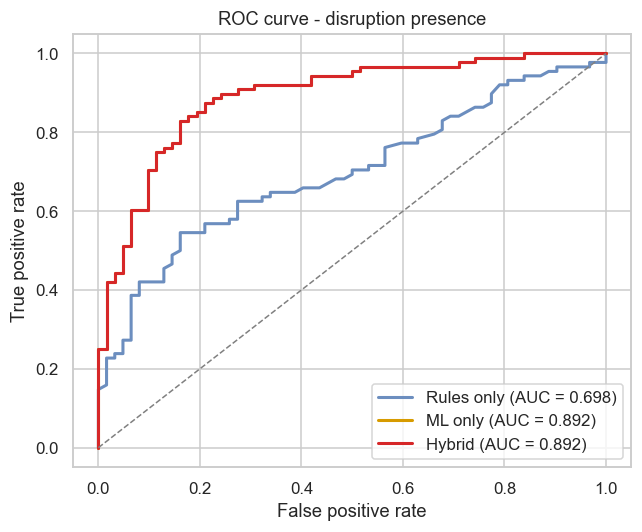

In [4]:
fig, ax = plt.subplots(figsize=(6, 5))
series = [
    ("Rules only", rules, "#6c8ebf"),
    ("ML only", ml, "#d79b00"),
    ("Hybrid", hybrid, "#d62728"),
]
for label, result, color in series:
    if not result:
        continue
    roc = result.get("curves", {}).get("roc")
    if not roc:
        continue
    auc = result["presence"]["roc_auc"]
    ax.plot(roc["fpr"], roc["tpr"], color=color, lw=2, label=f"{label} (AUC = {auc:.3f})")

ax.plot([0, 1], [0, 1], "--", color="gray", lw=1)
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC curve - disruption presence")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(PLOT_DIR / "roc_curve.png", bbox_inches="tight")
plt.show()

## 3. Precision-Recall curve

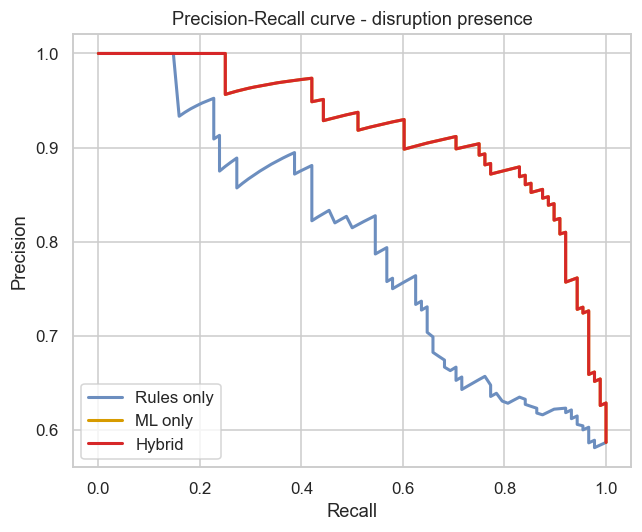

In [5]:
fig, ax = plt.subplots(figsize=(6, 5))
for label, result, color in series:
    if not result:
        continue
    pr = result.get("curves", {}).get("pr")
    if not pr:
        continue
    ax.plot(pr["recall"], pr["precision"], color=color, lw=2, label=label)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-Recall curve - disruption presence")
ax.legend(loc="lower left")
fig.tight_layout()
fig.savefig(PLOT_DIR / "precision_recall_curve.png", bbox_inches="tight")
plt.show()

## 4. Presence confusion matrices

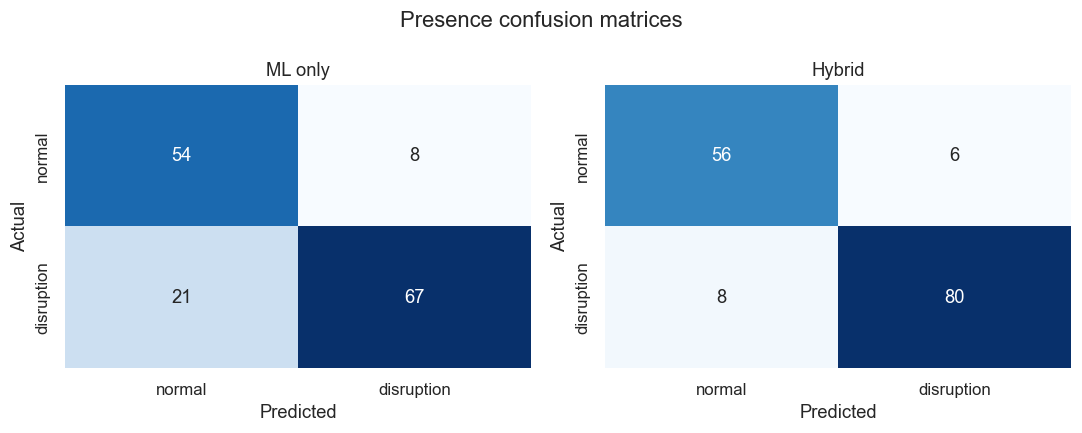

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
labels = ["normal", "disruption"]
for ax, (name, result) in zip(axes, [("ML only", ml), ("Hybrid", hybrid)]):
    if not result:
        ax.axis("off")
        continue
    cm = np.asarray(result["presence"]["confusion_matrix"])
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
        xticklabels=labels, yticklabels=labels,
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
fig.suptitle("Presence confusion matrices")
fig.tight_layout()
fig.savefig(PLOT_DIR / "confusion_matrices.png", bbox_inches="tight")
plt.show()

## 5. Severity confusion matrices

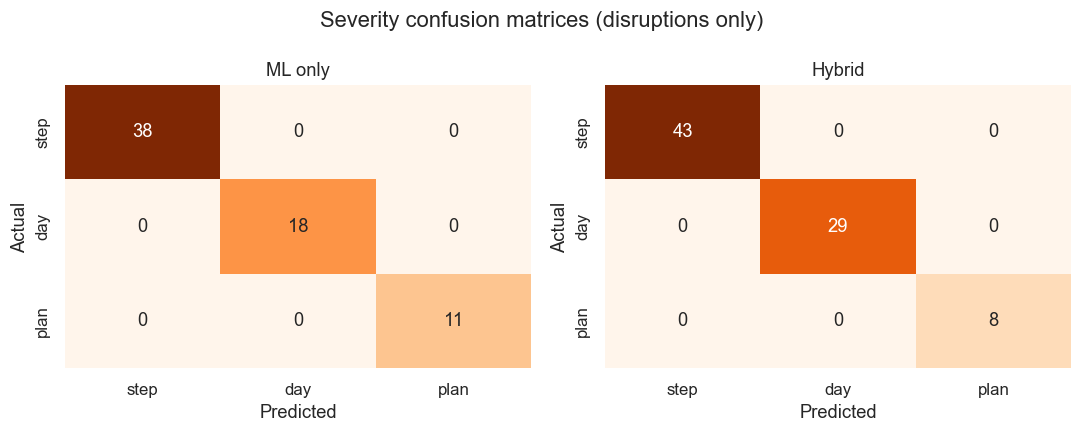

In [7]:
sev_labels = ["step", "day", "plan"]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, result) in zip(axes, [("ML only", ml), ("Hybrid", hybrid)]):
    if not result:
        ax.axis("off")
        continue
    cm = np.asarray(result["severity"]["confusion_matrix"])
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Oranges", cbar=False, ax=ax,
        xticklabels=sev_labels, yticklabels=sev_labels,
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
fig.suptitle("Severity confusion matrices (disruptions only)")
fig.tight_layout()
fig.savefig(PLOT_DIR / "severity_confusion_matrices.png", bbox_inches="tight")
plt.show()

## 6. Random Forest feature importance (severity model)

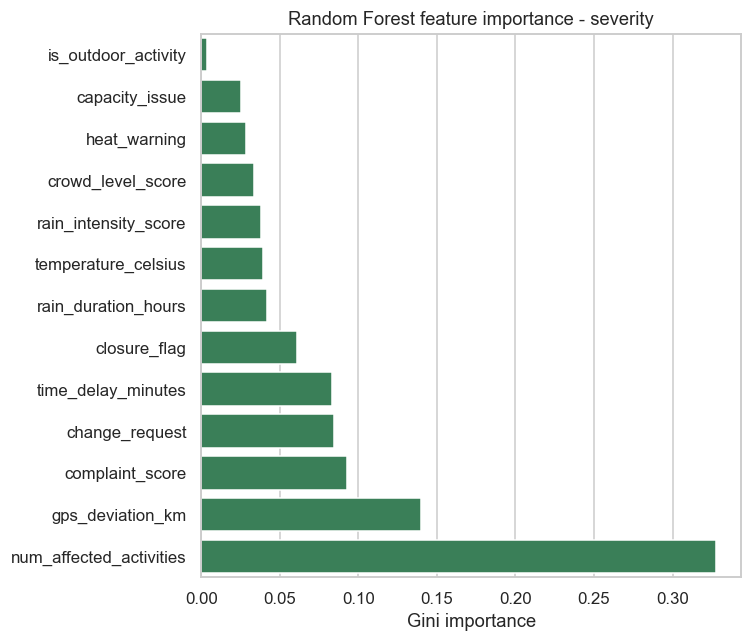

In [8]:
if train_severity and train_severity.get("feature_importance"):
    importance = (
        pd.Series(train_severity["feature_importance"])
        .sort_values(ascending=True)
    )
    fig, ax = plt.subplots(figsize=(7, 6))
    sns.barplot(x=importance.values, y=importance.index, ax=ax, color="#2e8b57")
    ax.set_xlabel("Gini importance")
    ax.set_ylabel("")
    ax.set_title("Random Forest feature importance - severity")
    fig.tight_layout()
    fig.savefig(PLOT_DIR / "feature_importance.png", bbox_inches="tight")
    plt.show()
else:
    print("[skip] no severity feature importance available")

## 7. Logistic Regression coefficients (presence model)

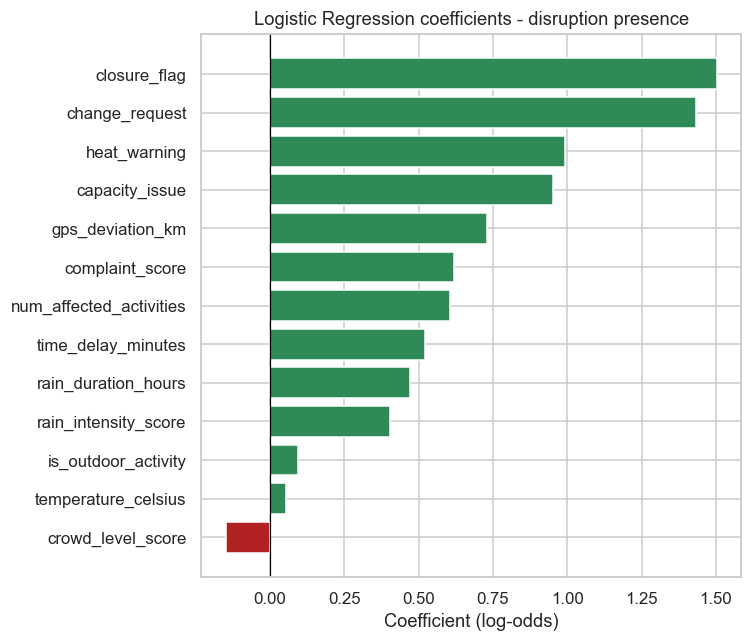

In [9]:
if train_presence and train_presence.get("coefficients"):
    coef = pd.Series(train_presence["coefficients"]).sort_values()
    colors = ["#b22222" if value < 0 else "#2e8b57" for value in coef.values]
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.barh(coef.index, coef.values, color=colors)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_xlabel("Coefficient (log-odds)")
    ax.set_title("Logistic Regression coefficients - disruption presence")
    fig.tight_layout()
    fig.savefig(PLOT_DIR / "coefficients.png", bbox_inches="tight")
    plt.show()
else:
    print("[skip] no presence coefficients available")

## 8. Ablation study (source contributions)

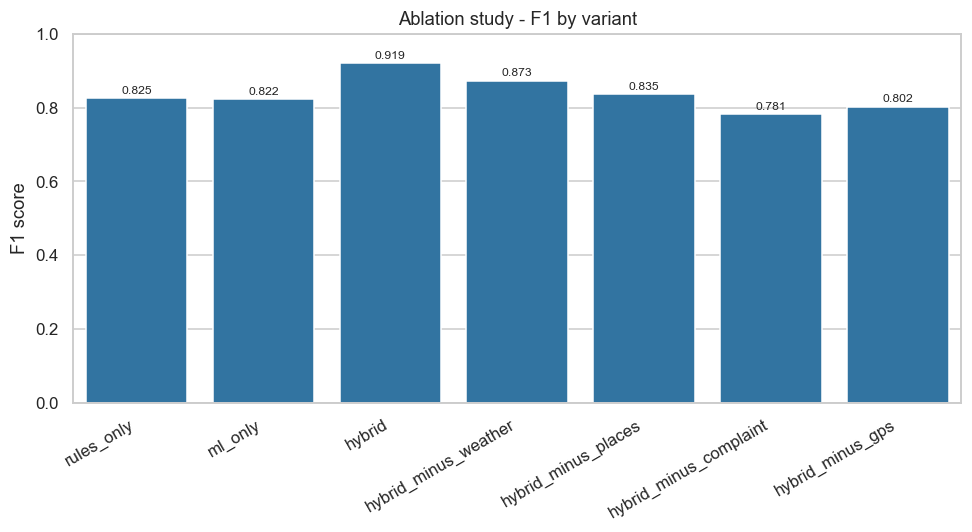

In [10]:
if ablation and ablation.get("results"):
    frame = pd.DataFrame(ablation["results"])
    fig, ax = plt.subplots(figsize=(9, 5))
    sns.barplot(data=frame, x="variant", y="f1", ax=ax, color="#1f77b4")
    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f", padding=2, fontsize=8)
    ax.set_ylim(0, 1.0)
    ax.set_xlabel("")
    ax.set_ylabel("F1 score")
    ax.set_title("Ablation study - F1 by variant")
    plt.xticks(rotation=30, ha="right")
    fig.tight_layout()
    fig.savefig(PLOT_DIR / "ablation.png", bbox_inches="tight")
    plt.show()
else:
    print("[skip] no ablation results available")

## 9. Inference latency

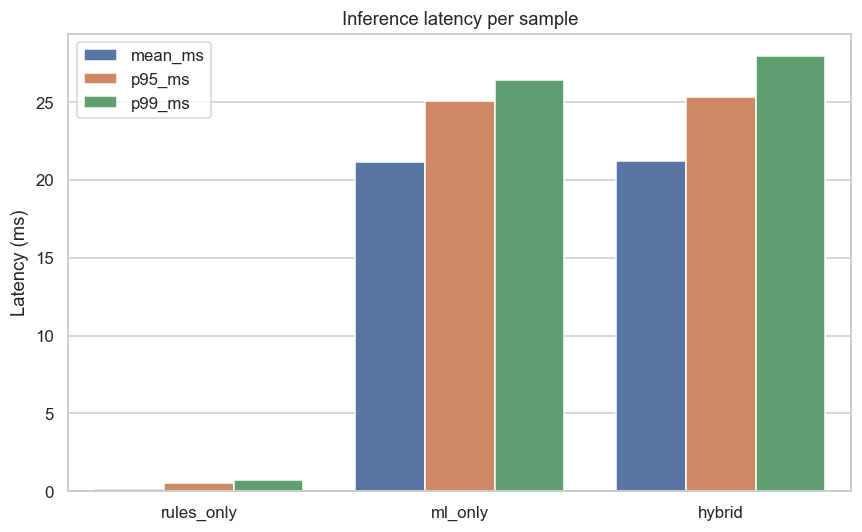

In [11]:
if latency and latency.get("results"):
    frame = pd.DataFrame(latency["results"])
    metrics = ["mean_ms", "p95_ms", "p99_ms"]
    melted = frame.melt(
        id_vars="variant", value_vars=metrics,
        var_name="metric", value_name="milliseconds",
    )
    fig, ax = plt.subplots(figsize=(8, 5))
    sns.barplot(data=melted, x="variant", y="milliseconds", hue="metric", ax=ax)
    ax.set_xlabel("")
    ax.set_ylabel("Latency (ms)")
    ax.set_title("Inference latency per sample")
    ax.legend(title="")
    fig.tight_layout()
    fig.savefig(PLOT_DIR / "latency.png", bbox_inches="tight")
    plt.show()
else:
    print("[skip] no latency results available")

## 10. Conclusion

In [12]:
conclusion = {
    "hybrid_f1": hybrid["presence"]["f1"] if hybrid else None,
    "ml_f1": ml["presence"]["f1"] if ml else None,
    "rules_f1": rules["presence"]["f1"] if rules else None,
}
improvement = None
if conclusion["hybrid_f1"] is not None and conclusion["rules_f1"] is not None:
    improvement = round(conclusion["hybrid_f1"] - conclusion["rules_f1"], 4)
conclusion["hybrid_minus_rules_f1"] = improvement

print("Hybrid F1:", conclusion["hybrid_f1"])
print("Rules-only F1:", conclusion["rules_f1"])
print("ML-only F1:", conclusion["ml_f1"])
print("Hybrid - rules F1:", improvement)
print("Figures written to:", PLOT_DIR)

Hybrid F1: 0.9195
Rules-only F1: 0.825
ML-only F1: 0.8221
Hybrid - rules F1: 0.0945
Figures written to: D:\Research\project\J26-DS-337\wandaraya-backend\data\disruption_detection\plots
